In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import xarray as xr
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

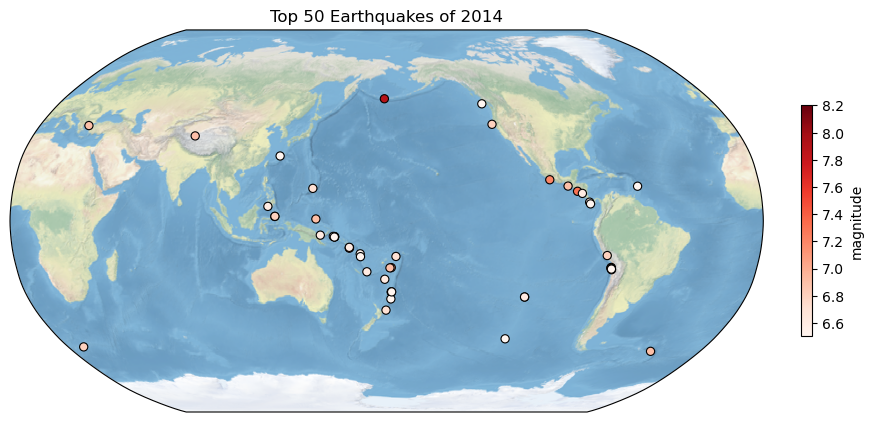

In [2]:
df = pd.read_csv("usgs_earthquakes.csv")

# 转换日期和震级，无法识别的值设为缺失值
df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)
df["mag"] = pd.to_numeric(df["mag"], errors="coerce")

# 筛选2014年的有效记录，选取震级最大的50次地震
df = df[df["time"].dt.year == 2014]
top50 = df.dropna(subset=["mag", "longitude", "latitude"]).nlargest(50, "mag")

# 中心设置为太平洋
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ax.set_global()
ax.stock_img()

# 绘制地震位置，颜色表示震级
points = ax.scatter(
    top50["longitude"], top50["latitude"],
    c=top50["mag"], cmap="Reds",
    s=35, edgecolors="black", linewidths=0.8,
    vmin=6.5, vmax=8.2,
    transform=ccrs.PlateCarree()
)

# 添加色标和标题
plt.colorbar(points, ax=ax, shrink=0.5, pad=0.04,ticks=[6.6, 6.8, 7.0, 7.2, 7.4, 7.6, 7.8, 8.0, 8.2],format="%.1f",label="magnitude")
ax.set_title("Top 50 Earthquakes of 2014")
plt.show()

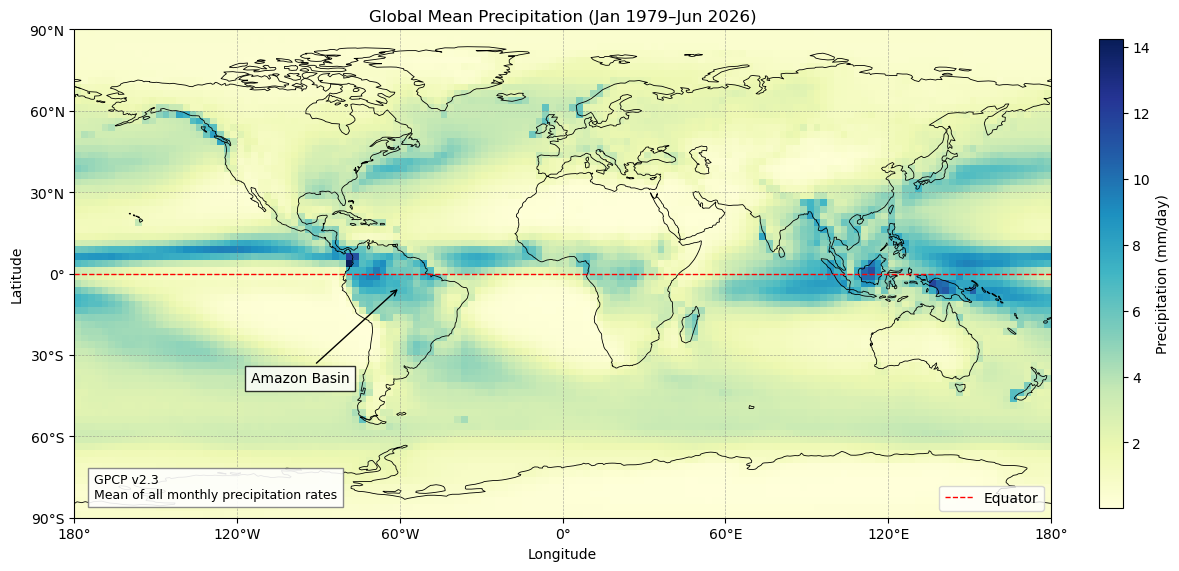

In [4]:
# 读取数据，跳过有问题的时间边界变量
ds = xr.open_dataset("precip.mon.mean.nc", drop_variables="time_bnds")

# 使用全部时间，计算各网格的多年平均降水率
rain_map = ds["precip"].mean("time", skipna=True)

# 将经度转换为-180到180度，并排序
rain_map = rain_map.assign_coords(lon=(rain_map["lon"] + 180) % 360 - 180).sortby("lon")

# 设置地图投影(project)
fig, ax = plt.subplots(
    figsize=(13, 7),
    subplot_kw={"projection": ccrs.PlateCarree()}
)
ax.set_global()

# 绘制降水空间分布
im = ax.pcolormesh(
    rain_map["lon"], rain_map["lat"], rain_map,
    transform=ccrs.PlateCarree(), cmap="YlGnBu", shading="auto"
)

# 横轴标签和刻度(x lable and ticket)
ax.set_xticks(range(-180, 181, 60), crs=ccrs.PlateCarree())
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.set_xlabel("Longitude")

# 纵轴标签和刻度(y lable and ticket)
ax.set_yticks(range(-90, 91, 30), crs=ccrs.PlateCarree())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.set_ylabel("Latitude")

# 标题(title)
ax.set_title("Global Mean Precipitation (Jan 1979–Jun 2026)")

# 经纬网格线(gridlines)
ax.gridlines(
    xlocs=range(-180, 181, 60), ylocs=range(-90, 91, 30),
    linewidth=0.5, color="gray", linestyle="--", alpha=0.6
)

# 图例：用红色虚线标出赤道(legend)
ax.plot(
    [-180, 180], [0, 0], color="red", linestyle="--",
    linewidth=1, transform=ccrs.PlateCarree(), label="Equator"
)
ax.legend(loc="lower right")

# 色标(colorbar)
fig.colorbar(im, ax=ax, shrink=0.7, pad=0.04,label="Precipitation (mm/day)")

# 地理要素：海岸线(features)
ax.coastlines(linewidth=0.6)

# 箭头注释：标出亚马孙盆地附近的位置(annotations)
ax.annotate(
    "Amazon Basin", xy=(-60, -5), xytext=(-115, -40),
    xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
    textcoords=ccrs.PlateCarree()._as_mpl_transform(ax),
    arrowprops={"arrowstyle": "->", "color": "black"},
    bbox={"facecolor": "white", "alpha": 0.8}
)

# 文本框：说明数据和计算方法(text box)
ax.text(
    0.02, 0.04, "GPCP v2.3\nMean of all monthly precipitation rates",
    transform=ax.transAxes, fontsize=9,
    bbox={"facecolor": "white", "edgecolor": "gray", "alpha": 0.9}
)

plt.tight_layout()
plt.show()

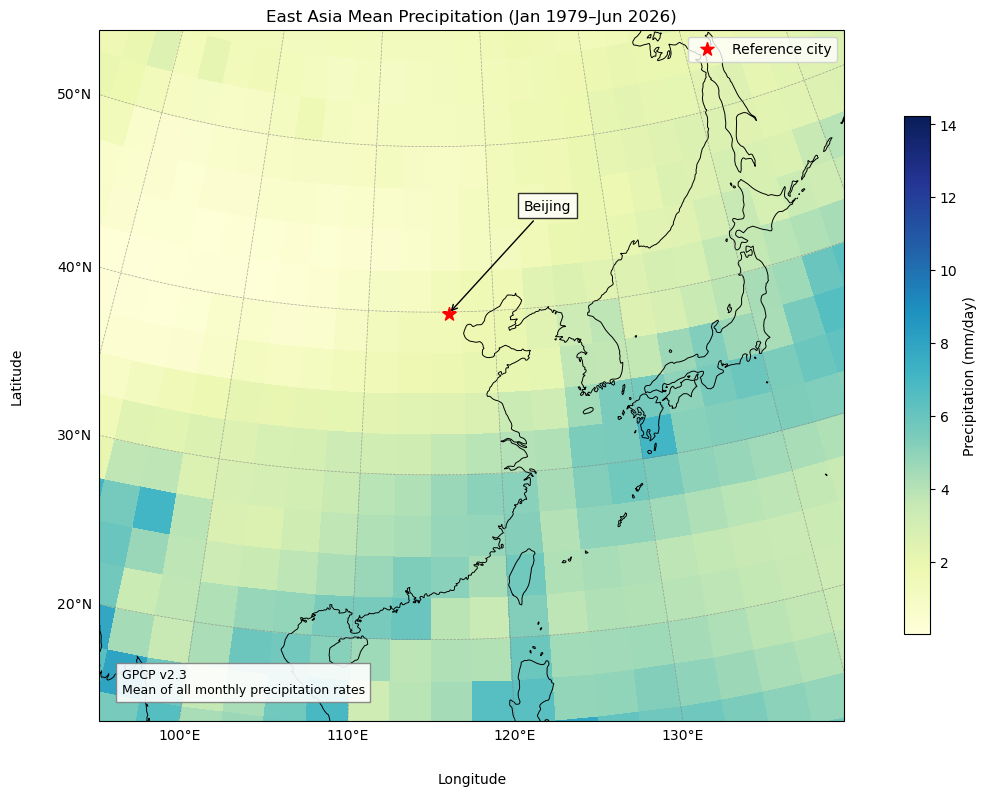

In [5]:
# 使用兰伯特等角圆锥投影(project)
fig, ax = plt.subplots(
    figsize=(11, 8),
    subplot_kw={"projection": ccrs.LambertConformal(
        central_longitude=115, central_latitude=35,
        standard_parallels=(25, 45)
    )}
)

# 设置东亚地区范围
ax.set_extent([95, 140, 15, 55], crs=ccrs.PlateCarree())

# 沿用上一题的rain_map绘制多年平均降水率
im = ax.pcolormesh(
    rain_map["lon"], rain_map["lat"], rain_map,
    transform=ccrs.PlateCarree(), cmap="YlGnBu", shading="auto"
)

# 设置经纬度刻度、标签和网格线(x,y,lable,gridlines)
gl = ax.gridlines(
    draw_labels=True, x_inline=False, y_inline=False,
    xlocs=range(90, 151, 10), ylocs=range(10, 61, 10),
    linewidth=0.5, linestyle="--", color="gray", alpha=0.7
)
gl.top_labels = False
gl.right_labels = False
gl.rotate_labels = False

ax.text(0.5, -0.09, "Longitude", transform=ax.transAxes, ha="center")
ax.text(-0.12, 0.5, "Latitude", transform=ax.transAxes,va="center", rotation=90)

# 添加标题(title)
ax.set_title("East Asia Mean Precipitation (Jan 1979–Jun 2026)")

# 图例：标记参考城市(legend)
ax.scatter(
    116.4, 39.9, color="red", marker="*", s=100,
    transform=ccrs.PlateCarree(), label="Reference city", zorder=5
)
ax.legend(loc="upper right")

# 色标(colorbar)
fig.colorbar(im, ax=ax, shrink=0.75, pad=0.06,label="Precipitation (mm/day)")

# 地理要素仍为海岸线(feature)
ax.coastlines(linewidth=0.7)

# 箭头注释北京(annotation)
ax.annotate(
    "Beijing", xy=(116.4, 39.9), xytext=(123, 46),
    xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
    textcoords=ccrs.PlateCarree()._as_mpl_transform(ax),
    arrowprops={"arrowstyle": "->"},
    bbox={"facecolor": "white", "alpha": 0.8}
)

# 文本框(text box)
ax.text(
    0.03, 0.04, "GPCP v2.3\nMean of all monthly precipitation rates",
    transform=ax.transAxes, fontsize=9,
    bbox={"facecolor": "white", "edgecolor": "gray", "alpha": 0.9}
)

plt.tight_layout()
plt.show()